# Phase 2 Temporal Baseline Modeling

Reproducible analysis of Development only. Production is reserved. Read PHASE_2_MODELING_REPORT.md for completed execution details.

## Completed run summary

| model | pr_auc | roc_auc |
| --- | --- | --- |
| Dummy | 0.000621 | 0.500000 |
| LogisticRegression | 0.998850 | 0.999525 |
| RandomForest | 0.999997 | 1.000000 |
| XGBoost | 0.999760 | 1.000000 |
| LightGBM | 0.999993 | 1.000000 |

Train: 4,388,788 rows, 3,609 frauds. Validation: 1,398,242 rows, 868 frauds. Runtime 2.51 minutes.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
run = json.loads((ROOT / 'artifacts/phase2_run.json').read_text())
comparison = pd.read_csv(ROOT / 'artifacts/baseline_model_comparison.csv')


## Temporal strategy

First 80% of fixed Development steps, verified for at least 100 frauds in each segment. Cutoff is not optimized by predictive results. Validation remains untouched.

,rows,frauds,prevalence,step_min,step_max
train,4388788.0,3609.0,0.000822,1.0,320.0
validation,1398242.0,868.0,0.000621,321.0,400.0


,step,transactions,frauds,fraud_rate
0,1,2708,16,0.005908
1,2,1014,8,0.007890
2,3,552,4,0.007246
3,4,565,10,0.017699
4,5,665,6,0.009023
5,6,1660,22,0.013253
6,7,6837,12,0.001755
7,8,21097,12,0.000569
8,9,37628,19,0.000505
9,10,35991,11,0.000306


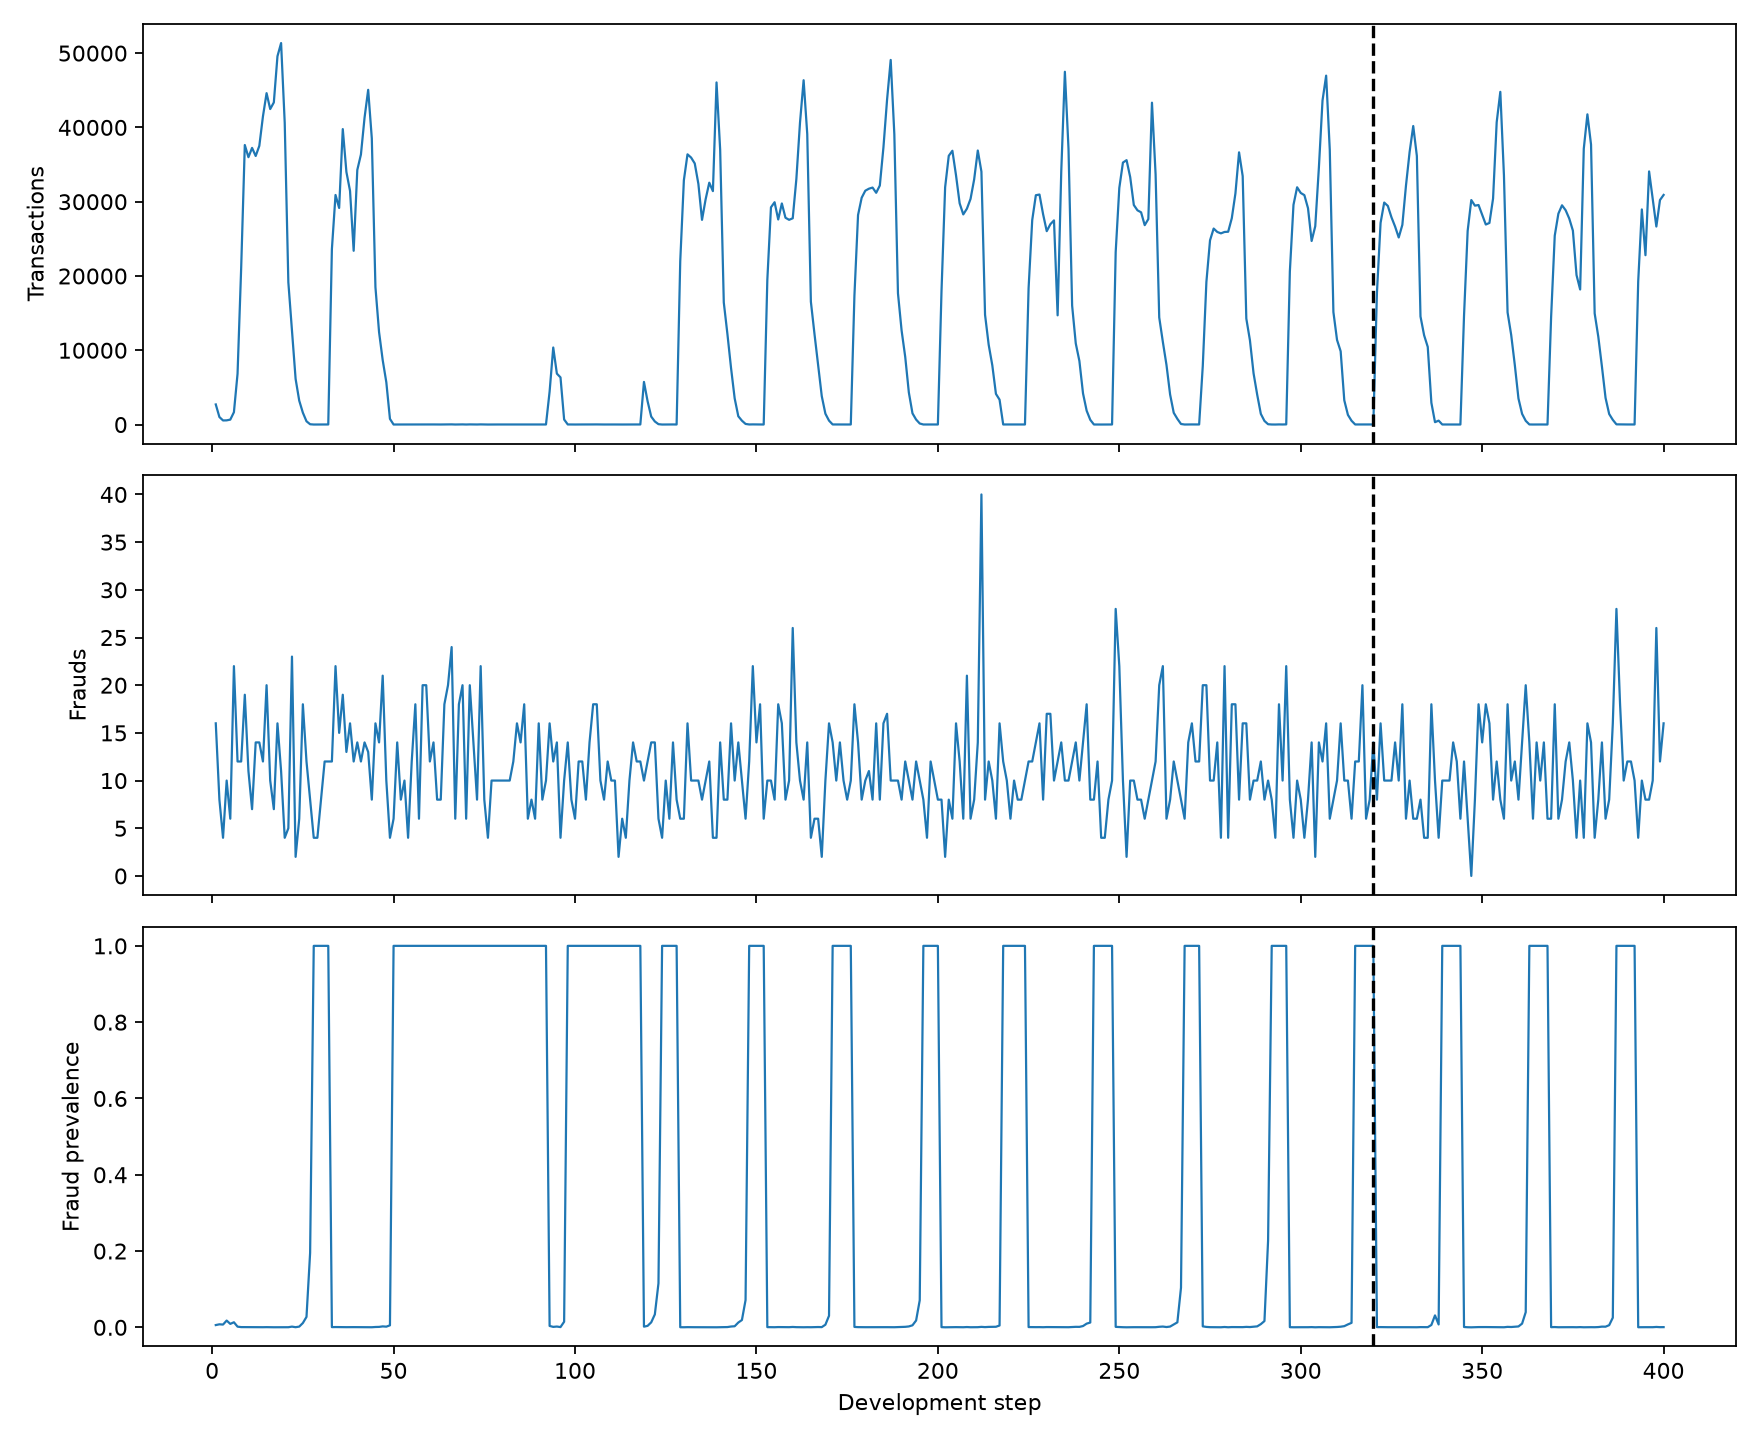

In [2]:
display(pd.DataFrame(run['split']).T)
profile = pd.read_csv(ROOT / 'artifacts/development_temporal_profile.csv')
display(profile)
display(Image(filename=str(ROOT / 'reports/figures/development_temporal.png')))

## Feature availability and leakage

Principal scoring occurs before execution. Post-event balances/residuals, raw IDs, business rule and label are excluded. Ratio uses an explicit zero sentinel and indicator. Emptying tolerance is absolute 0.01. No target encoding or future aggregates.

In [3]:
display(run['features'])
display(Markdown((ROOT / 'docs/feature_catalog.md').read_text(encoding='utf-8-sig')))
display(run['business_rule'])

['step', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'amount_to_oldbalanceOrg', 'orig_balance_zero', 'orig_balance_emptied', 'dest_is_merchant', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'type_UNKNOWN']

# Feature catalog and leakage review

Principal scoring assumption: immediately before executing the transaction. Previous balances, requested amount, transaction type and destination identifier are assumed available. This is an academic assumption requiring operational confirmation before deployment. Post-event candidates are implemented for review but excluded from every principal benchmark.

| Feature | Source and formula | Availability | Risk | Decision |
|---|---|---|---|---|
| step | Original simulation step | Before execution | Time trend may not generalize beyond development | INCLUDE |
| amount | Requested amount | Before execution | Validate domain and units | INCLUDE |
| oldbalanceOrg | Previous origin balance | Before execution, assumed | Operational availability needs confirmation | INCLUDE |
| oldbalanceDest | Previous destination balance | Before execution, assumed | May be unavailable across institutions | INCLUDE |
| amount_to_oldbalanceOrg | amount / oldbalanceOrg; zero denominator returns 0 plus orig_balance_zero | Before execution | Sentinel must be interpreted with indicator; no NaN/inf | INCLUDE |
| orig_balance_zero | oldbalanceOrg == 0 | Before execution | No future or label dependence | INCLUDE |
| orig_balance_emptied | oldbalanceOrg > 0 and abs(amount - oldbalanceOrg) <= 0.01 | Before execution | Requested amount approximately consumes balance; does not prove actual completion | INCLUDE |
| dest_is_merchant | nameDest begins with M | Before execution | Structural simulation proxy; prefix semantics require real-world validation | INCLUDE |
| type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER | Fixed domain vocabulary indicators | Before execution | No fitted categories or target encoding; includes all types | INCLUDE |
| type_UNKNOWN | Type outside fixed vocabulary | Before execution | All observed training values covered; explicit unseen-type handling | INCLUDE |
| newbalanceOrig, newbalanceDest | Balance after operation | After execution | Future event information for pre-execution scoring | EXCLUDE |
| orig_balance_diff | oldbalanceOrg - newbalanceOrig; positive means net origin decrease | After execution | Post-event leakage | REVIEW; excluded |
| dest_balance_diff | newbalanceDest - oldbalanceDest; positive means net destination increase | After execution | Post-event leakage | REVIEW; excluded |
| orig_balance_error | orig_balance_diff - amount for TRANSFER/CASH_OUT, else 0 | After execution | Post-event leakage; other transaction directions differ | REVIEW; excluded |
| dest_balance_error | dest_balance_diff - amount for TRANSFER/CASH_OUT, else 0 | After execution | Post-event leakage; simulation balance conventions can create residuals | REVIEW; excluded |
| nameOrig, nameDest raw | High-cardinality IDs | Before execution | Memorization and temporal leakage from global target encoding | EXCLUDE raw IDs |
| isFlaggedFraud | Existing business rule | Rule dependent | Benchmark excludes existing decision signal by instruction | EXCLUDE; descriptive analysis only |
| isFraud | Label | Outcome label | Direct leakage | EXCLUDE predictor; target only |

No global entity statistics, future aggregates, resampling or label-derived features are used. Row-local transformations produce identical results independent of future rows. StandardScaler is fitted solely on Train in the logistic pipeline. Fixed encoding is not learned from Validation or Production. All 14 final model columns are explicitly ordered in MODEL_COLUMNS; only those are saved as model matrices.

Zero denominators retain finite ratios using a zero sentinel plus a dedicated indicator, rather than adding an arbitrary epsilon. The 0.01 emptying tolerance is absolute, with no relative tolerance. Ratios and monetary values are calculated in float64, then model matrices are persisted as float32 for memory efficiency; precision loss at large amounts is a limitation. Raw CSV remains intact.

Production rows are filtered in each input chunk before concatenation, profiling, feature generation or model fitting. Reading the CSV stream to apply its step filter is not Production evaluation. No Production statistics are generated by Phase 2.


{'train': {'flagged': 3, 'true_fraud': 3, 'precision': 1.0, 'recall': 0.0008312551953449709}, 'validation': {'flagged': 1, 'true_fraud': 1, 'precision': 1.0, 'recall': 0.001152073732718894}}

## Fixed baselines

Dummy, scaled weighted logistic regression, weighted Random Forest, XGBoost and LightGBM. Full Train for all; no optimization or resampling. Configurations are recorded by the training script.

In [4]:
display(run['configurations'])
display(comparison)

{'Dummy': {'constant': 'None', 'random_state': '42', 'strategy': 'prior'}, 'LogisticRegression': {'memory': 'None', 'steps': "[('standardscaler', StandardScaler()), ('logisticregression', LogisticRegression(class_weight='balanced', max_iter=400, random_state=42))]", 'transform_input': 'None', 'verbose': 'False', 'standardscaler': 'StandardScaler()', 'logisticregression': "LogisticRegression(class_weight='balanced', max_iter=400, random_state=42)", 'standardscaler__copy': 'True', 'standardscaler__with_mean': 'True', 'standardscaler__with_std': 'True', 'logisticregression__C': '1.0', 'logisticregression__class_weight': 'balanced', 'logisticregression__dual': 'False', 'logisticregression__fit_intercept': 'True', 'logisticregression__intercept_scaling': '1', 'logisticregression__l1_ratio': '0.0', 'logisticregression__max_iter': '400', 'logisticregression__n_jobs': 'None', 'logisticregression__penalty': 'deprecated', 'logisticregression__random_state': '42', 'logisticregression__solver': 'l

,model,train_observations,validation_observations,training_seconds,prediction_seconds,pr_auc,roc_auc,precision_05,recall_05,f1_05,f2_05,tp,fp,tn,fn,k_0.1pct,precision_top_0.1pct,recall_top_0.1pct,k_0.5pct,precision_top_0.5pct,recall_top_0.5pct,k_1pct,precision_top_1pct,recall_top_1pct
0,Dummy,4388788,1398242,0.183975,0.077118,0.000621,0.500000,0.000000,0.000000,0.000000,0.000000,0,0,1397374,868,1399,0.000000,0.000000,6992,0.000286,0.002304,13983,0.000429,0.006912
1,LogisticRegression,4388788,1398242,10.116063,0.189498,0.998850,0.999525,0.997699,0.998848,0.998273,0.998618,867,2,1397372,1,1399,0.619728,0.998848,6992,0.123999,0.998848,13983,0.062004,0.998848
2,RandomForest,4388788,1398242,77.542323,0.610391,0.999997,1.000000,0.996556,1.000000,0.998275,0.999309,868,3,1397371,0,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.000000
3,XGBoost,4388788,1398242,13.524489,0.558082,0.999760,1.000000,1.000000,0.998848,0.999424,0.999078,867,0,1397374,1,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.000000
4,LightGBM,4388788,1398242,11.971916,1.421617,0.999993,1.000000,1.000000,0.997696,0.998847,0.998156,866,0,1397374,2,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.000000


## Validation comparison

Average Precision is the primary metric; ROC-AUC is secondary. Threshold 0.5 is a benchmark convention, not a production decision. Very high scores in a simulator warrant domain review.

,model,pr_auc,roc_auc,precision_05,recall_05,f1_05,f2_05
0,Dummy,0.000621,0.500000,0.000000,0.000000,0.000000,0.000000
1,LogisticRegression,0.998850,0.999525,0.997699,0.998848,0.998273,0.998618
2,RandomForest,0.999997,1.000000,0.996556,1.000000,0.998275,0.999309
3,XGBoost,0.999760,1.000000,1.000000,0.998848,0.999424,0.999078
4,LightGBM,0.999993,1.000000,1.000000,0.997696,0.998847,0.998156


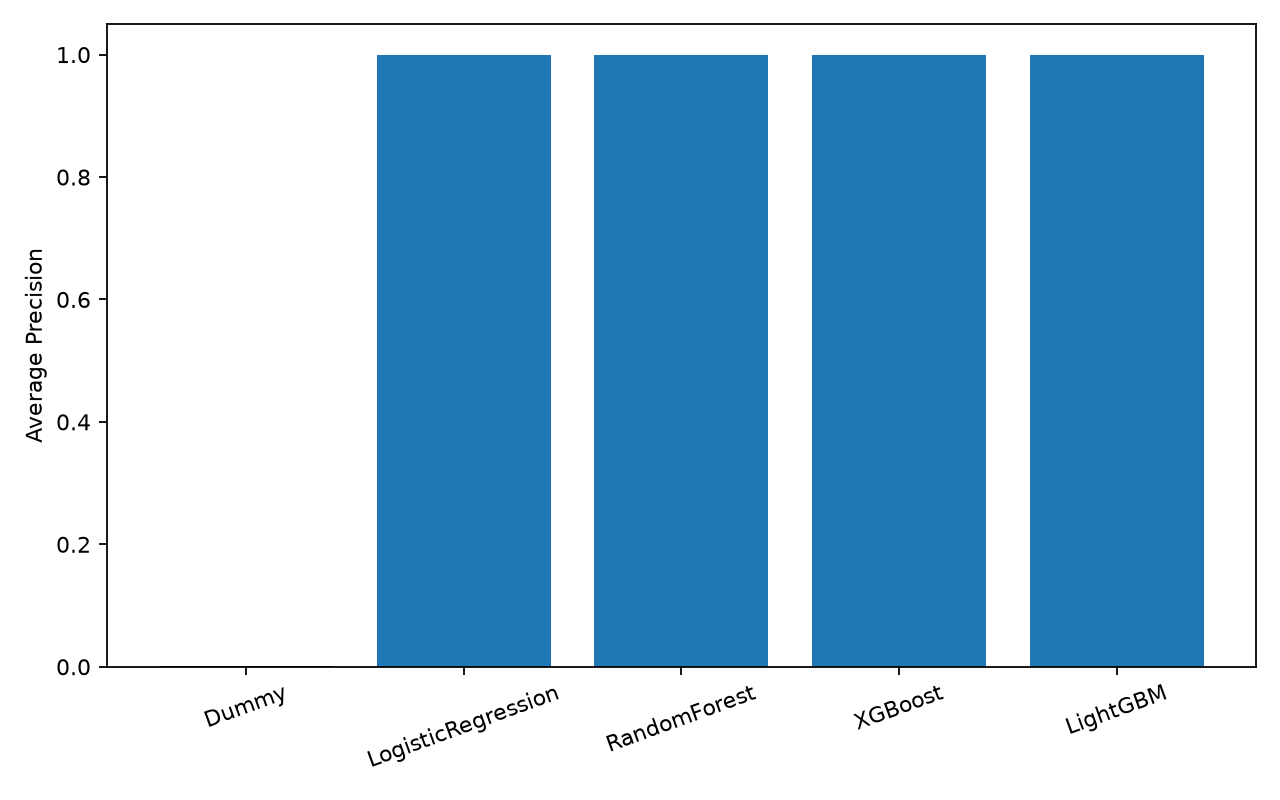

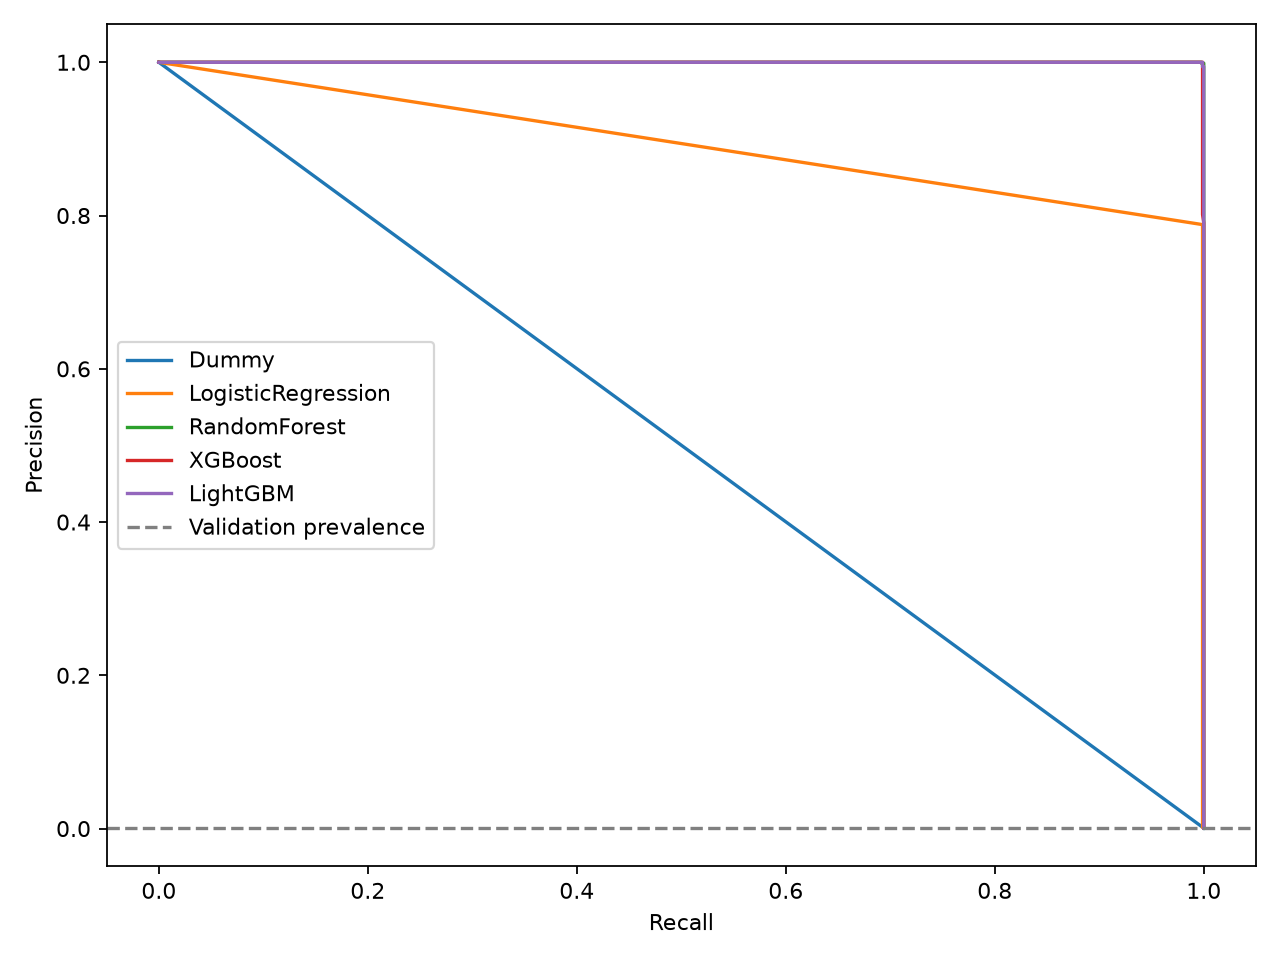

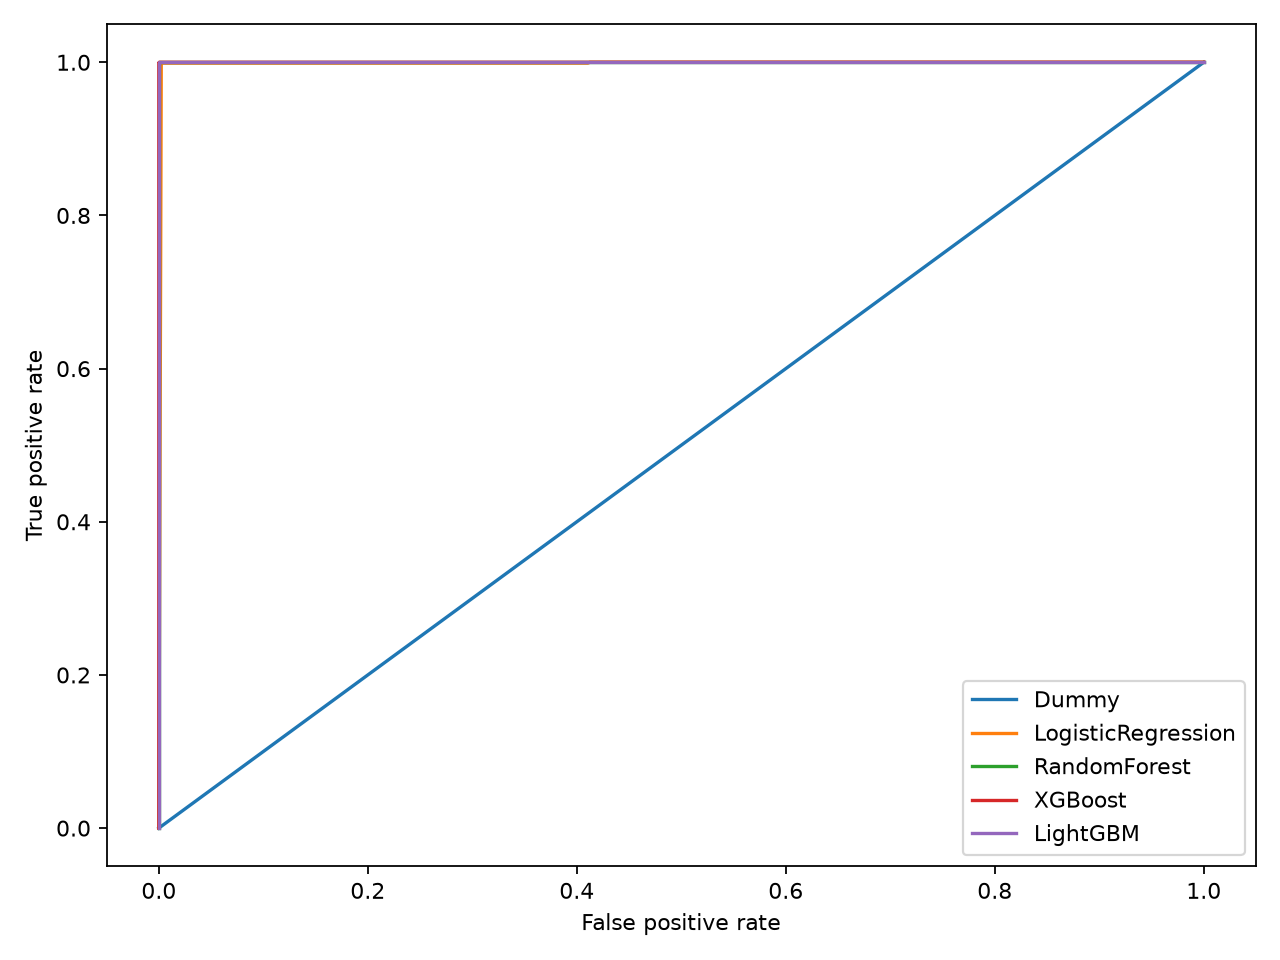

In [5]:
display(comparison[['model','pr_auc','roc_auc','precision_05','recall_05','f1_05','f2_05']])
for figure in ['average_precision_comparison.png','precision_recall.png','roc.png']:
    display(Image(filename=str(ROOT / 'reports/figures' / figure)))

## Operational review capacity

Recall@Top-K measures the share of Validation frauds captured if only the top X% can be reviewed. Precision measures yield among reviewed transactions. Stable row-order ties make Dummy ranking incidental.

,model,k_0.1pct,precision_top_0.1pct,recall_top_0.1pct,k_0.5pct,precision_top_0.5pct,recall_top_0.5pct,k_1pct,precision_top_1pct,recall_top_1pct
0,Dummy,1399,0.000000,0.000000,6992,0.000286,0.002304,13983,0.000429,0.006912
1,LogisticRegression,1399,0.619728,0.998848,6992,0.123999,0.998848,13983,0.062004,0.998848
2,RandomForest,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.000000
3,XGBoost,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.000000
4,LightGBM,1399,0.620443,1.000000,6992,0.124142,1.000000,13983,0.062075,1.000000


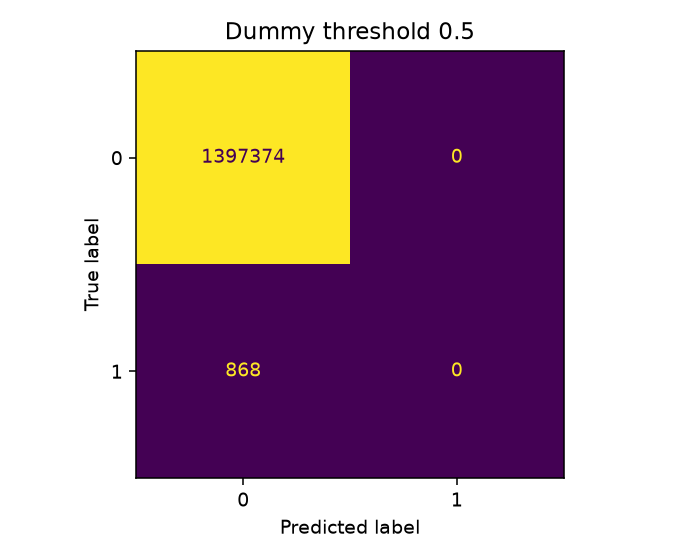

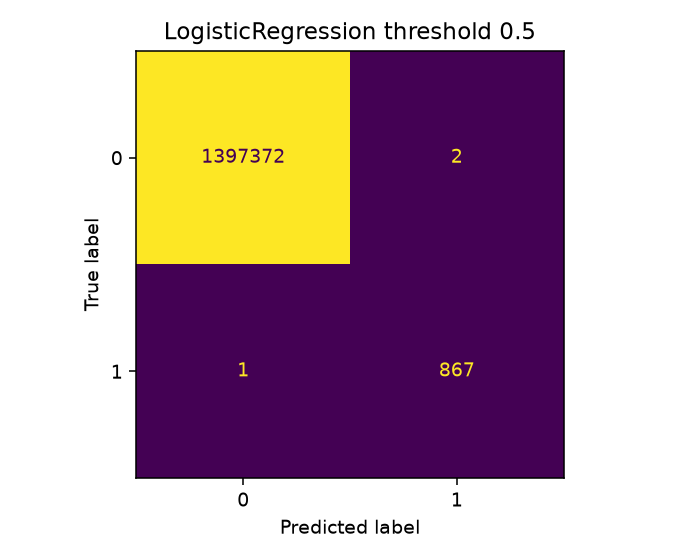

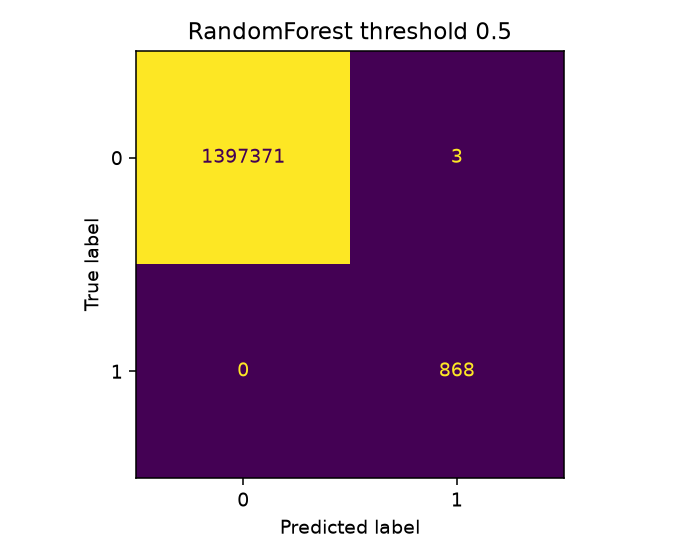

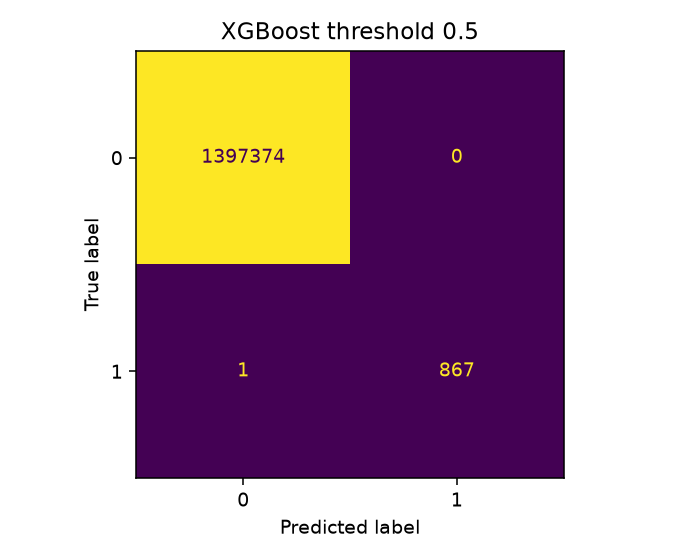

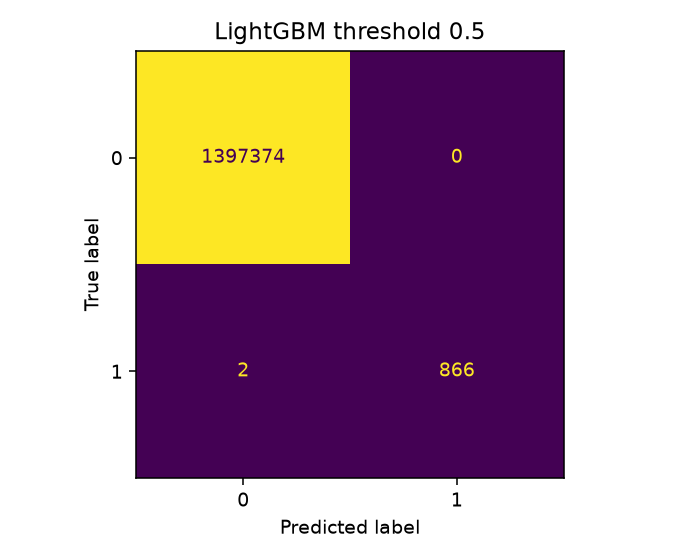

In [6]:
display(comparison[['model'] + [c for c in comparison.columns if 'top_' in c or c.startswith('k_')]])
for name in comparison.model:
    display(Image(filename=str(ROOT / 'reports/figures' / f'confusion_{name}.png')))

## Reproduce and stop at Phase 2

Run `uv sync --locked`, `uv run python -m pytest -q`, `uv run python scripts/run_baselines.py`, then `uv run python scripts/build_phase2_report.py` from the repository root. For datasets only add `--prepare-only` to run_baselines.py. No champion, tuning, monitoring or Production evaluation is part of this notebook.